# Aliasing blind spots: out-of-distribution detection in data re-uploading QNNs

This notebook runs the full study end to end and, in its last cell, zips every result
(CSV tables, per-sample scores, figures, config, logs) into one file for further analysis.

**What it tests**

1. **Alias theorem (exact).** With integer-frequency angle encodings, every QNN output is
   2π-periodic in each encoded coordinate. Therefore *every* score built only from models that share
   the encoding is periodic too: max-probability, energy, ensemble variance, MC parameter-noise
   variance, and parameter-gradient ("extrapolation") scores. On the exact alias set
   `u + 2πk` they must give AUROC = 0.5 exactly. Experiment E0/E2 verifies this numerically.
2. **How often real shifts land on aliases.** Shifted test points are wrapped onto the torus and
   checked against the training support. We report the fraction out of range, the fraction
   aliased, and the torus coverage of the training data for two common min–max ranges:
   `sym` = [−π, π] (training fills the whole period) and `half` = [0, π] (half the period).
3. **Fixes.** (a) squashing pre-map `(π/2)·tanh(z/s)`, (b) trainable incommensurate frequencies
   (quasi-periodic, so aliasing becomes *approximate*; we measure the recurrence distance),
   (c) distance-aware hybrid head (logits gated by kNN distance in raw feature space).
4. **Baselines.** MLP (+ensemble), RBF-SVM, Gaussian process, random-Fourier-feature model on the
   QNN's integer spectrum (a classical periodic control), kNN distance, QNN ensembles and
   Gaussian parameter noise ("Gaussian dropout").

**Simulator.** Exact statevector simulation in NumPy with adjoint-method gradients
(verified against finite differences in E0). No PyTorch/PennyLane needed.

**Run:** set `MODE` in the config cell (`"FAST"` ≈ 10–20 min smoke test, `"FULL"` = paper run),
then *Run All*. Interrupted runs resume from `results/parts/`.

In [1]:
# Install dependencies if missing (Colab already has them).
import importlib, subprocess, sys
for _pkg in ["numpy", "scipy", "pandas", "matplotlib", "sklearn"]:
    try:
        importlib.import_module(_pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                               "scikit-learn" if _pkg == "sklearn" else _pkg])

In [2]:
import os, json, time, math, zipfile, shutil, warnings, platform, datetime, traceback
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.special import logsumexp, softmax
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.neighbors import NearestNeighbors
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.gaussian_process.kernels import RBF, ConstantKernel
from sklearn.linear_model import LogisticRegression

warnings.filterwarnings("ignore")
TWO_PI = 2 * np.pi

## Configuration

In [3]:
MODE = "FULL"   # "FAST" for a quick smoke test, "FULL" for the paper run

DATASETS = ["synth2d", "wine_red_white", "mnist_fmnist", "covertype", "digits_split"]

COMMON = dict(
    scalings={"sym": (-np.pi, np.pi), "half": (0.0, np.pi)},  # min-max target ranges for the angle encoding
    squash_s=3.0,          # squash pre-map: (pi/2) * tanh(z / squash_s), z = standardized feature
    lr=0.05, batch=64,
    gdrop_sigma=0.15,      # Gaussian parameter-noise std (train + MC test)
    mc_samples=10,
    knn_k=10,
    rff_features=300,
    gp_max_train=600,
    resume=True,
    save_per_sample_scores=True,
    data_home="./data_cache",
    results_dir="./results",
)
PRESETS = {
    "FAST": dict(seeds=[0], n_train=600, n_test=300, epochs=15, n_layers=3, ens_size=3,
                 translate=[1.0, 4.0], scale=[2.0, 4.0], recurrence_shifts=600, recurrence_points=60,
                 grid=120),
    "FULL": dict(seeds=[0, 1, 2], n_train=2000, n_test=1000, epochs=40, n_layers=4, ens_size=5,
                 translate=[0.5, 1.0, 2.0, 4.0, 8.0], scale=[1.5, 2.0, 4.0, 8.0],
                 recurrence_shifts=1500, recurrence_points=150, grid=200),
}
CFG = {**COMMON, **PRESETS[MODE], "mode": MODE, "datasets": DATASETS}
QUBITS = {"synth2d": 4}          # 2 features tiled on 4 qubits; all other datasets use 8 qubits / 8 PCA features
DEFAULT_QUBITS = 8
PCA_DIM = 8

RES = CFG["results_dir"]
for sub in ["", "parts", "figures", "scores"]:
    os.makedirs(os.path.join(RES, sub), exist_ok=True)
LOG_PATH = os.path.join(RES, "run_log.txt")

def log(msg):
    line = f"[{datetime.datetime.now().strftime('%H:%M:%S')}] {msg}"
    print(line, flush=True)
    with open(LOG_PATH, "a") as f:
        f.write(line + "\n")

with open(os.path.join(RES, "config.json"), "w") as f:
    json.dump({k: (v if not isinstance(v, dict) else {kk: list(vv) if isinstance(vv, tuple) else vv
                                                     for kk, vv in v.items()}) for k, v in CFG.items()},
              f, indent=2, default=str)
log(f"MODE={MODE}  datasets={DATASETS}  seeds={CFG['seeds']}")

[12:37:04] MODE=FULL  datasets=['synth2d', 'wine_red_white', 'mnist_fmnist', 'covertype', 'digits_split']  seeds=[0, 1, 2]


## Statevector QNN with adjoint gradients

Layer *l*: `RX(ω_{l,q} · u_{f(q)})` on every qubit q (feature f(q) = q mod d, so features are tiled),
then trainable `RY(θ)`, `RZ(φ)` on every qubit, then a CNOT ring. Readout: ⟨Z_q⟩ for all qubits →
trainable linear head → logits. With ω ≡ 1 the model is exactly 2π-periodic in every input coordinate.

In [4]:
class Circuit:
    def __init__(self, n_qubits, n_layers, n_features):
        self.n, self.L, self.d = n_qubits, n_layers, n_features
        self.dim = 2 ** n_qubits
        self.fq = np.arange(n_qubits) % n_features
        idx = np.arange(self.dim)
        bits = (idx[:, None] >> (n_qubits - 1 - np.arange(n_qubits))[None, :]) & 1   # qubit 0 = MSB
        self.zsign = (1 - 2 * bits).astype(float)          # (dim, n)
        g = idx.copy()
        if n_qubits > 1:
            pairs = [(q, (q + 1) % n_qubits) for q in range(n_qubits)] if n_qubits > 2 else [(0, 1)]
            for c, t in pairs:
                f = idx.copy()
                cb = (idx >> (n_qubits - 1 - c)) & 1
                f[cb == 1] = idx[cb == 1] ^ (1 << (n_qubits - 1 - t))
                g = g[f]
        self.perm, self.perm_inv = g, np.argsort(g)

    # --- gate primitives on batched states psi (B, dim) ---
    def _apply(self, psi, U00, U01, U10, U11, q):
        B = psi.shape[0]
        p = psi.reshape(B, 2 ** q, 2, 2 ** (self.n - q - 1))
        a0, a1 = p[:, :, 0, :], p[:, :, 1, :]
        out = np.empty_like(p)
        out[:, :, 0, :] = U00 * a0 + U01 * a1
        out[:, :, 1, :] = U10 * a0 + U11 * a1
        return out.reshape(B, -1)

    def rx(self, psi, a, q):        # a: (B,) or scalar
        a = np.asarray(a, float)
        c, s = np.cos(a / 2), np.sin(a / 2)
        if a.ndim:
            c, s = c[:, None, None], s[:, None, None]
        return self._apply(psi, c, -1j * s, -1j * s, c, q)

    def ry(self, psi, a, q):
        c, s = np.cos(a / 2), np.sin(a / 2)
        return self._apply(psi, c, -s, s, c, q)

    def rz(self, psi, a, q):
        return psi * np.exp(-0.5j * a * self.zsign[:, q])[None, :]

    def gx(self, psi, q):
        return self._apply(psi, 0, 1, 1, 0, q)

    def gy(self, psi, q):
        return self._apply(psi, 0, -1j, 1j, 0, q)

    def forward(self, u, theta, omega):
        B = u.shape[0]
        psi = np.zeros((B, self.dim), complex)
        psi[:, 0] = 1.0
        ang = u[:, self.fq]
        for l in range(self.L):
            for q in range(self.n):
                psi = self.rx(psi, omega[l, q] * ang[:, q], q)
            for q in range(self.n):
                psi = self.ry(psi, theta[l, q, 0], q)
                psi = self.rz(psi, theta[l, q, 1], q)
            psi = psi[:, self.perm]
        z = (np.abs(psi) ** 2) @ self.zsign
        return z, psi

    def backward(self, u, theta, omega, psi, c):
        """Adjoint method. c: (B, n) = dLoss_b / d<Z_q>_b. Returns per-sample grads."""
        B = u.shape[0]
        ang = u[:, self.fq]
        lam = psi * (c @ self.zsign.T)
        g_th = np.zeros((B, self.L, self.n, 2))
        g_om = np.zeros((B, self.L, self.n))
        for l in reversed(range(self.L)):
            psi, lam = psi[:, self.perm_inv], lam[:, self.perm_inv]
            for q in reversed(range(self.n)):
                g_th[:, l, q, 1] = np.imag(np.sum(np.conj(lam) * psi * self.zsign[:, q][None, :], 1))
                psi, lam = self.rz(psi, -theta[l, q, 1], q), self.rz(lam, -theta[l, q, 1], q)
                g_th[:, l, q, 0] = np.imag(np.sum(np.conj(lam) * self.gy(psi, q), 1))
                psi, lam = self.ry(psi, -theta[l, q, 0], q), self.ry(lam, -theta[l, q, 0], q)
            for q in reversed(range(self.n)):
                ga = np.imag(np.sum(np.conj(lam) * self.gx(psi, q), 1))
                g_om[:, l, q] = ga * ang[:, q]
                a = omega[l, q] * ang[:, q]
                psi, lam = self.rx(psi, -a, q), self.rx(lam, -a, q)
        # factor 2 from E = <psi|O|psi>: dE/dθ = Im<λ|G|ψ> already includes it for U = exp(-iθG/2)
        return g_th, g_om


class Adam:
    def __init__(self, params, lr):
        self.lr, self.t = lr, 0
        self.m = {k: np.zeros_like(v) for k, v in params.items()}
        self.v = {k: np.zeros_like(v) for k, v in params.items()}

    def step(self, params, grads, b1=0.9, b2=0.999, eps=1e-8):
        self.t += 1
        for k in grads:
            self.m[k] = b1 * self.m[k] + (1 - b1) * grads[k]
            self.v[k] = b2 * self.v[k] + (1 - b2) * grads[k] ** 2
            mh, vh = self.m[k] / (1 - b1 ** self.t), self.v[k] / (1 - b2 ** self.t)
            params[k] -= self.lr * mh / (np.sqrt(vh) + eps)


def golden_freqs(L, n):
    k = np.arange(1, L * n + 1).reshape(L, n)
    return 1.0 + 0.8 * (((k * 0.6180339887498949) % 1.0) - 0.5)   # in [0.6, 1.4], pairwise incommensurate


class QNN:
    """Data re-uploading classifier. trainable_freq=True -> incommensurate trainable frequencies."""
    def __init__(self, n_qubits, n_layers, n_features, n_classes, trainable_freq=False,
                 param_noise=0.0, seed=0, lr=0.05):
        self.circ = Circuit(n_qubits, n_layers, n_features)
        self.C, self.trainable_freq, self.param_noise = n_classes, trainable_freq, param_noise
        self.rng = np.random.default_rng(seed)
        r = self.rng
        self.p = {
            "theta": r.normal(0, 1.0, (n_layers, n_qubits, 2)),
            "omega": golden_freqs(n_layers, n_qubits) if trainable_freq else np.ones((n_layers, n_qubits)),
            "W": r.normal(0, 1.0, (n_classes, n_qubits)),
            "b": np.zeros(n_classes),
        }
        self.lr = lr

    def _logits(self, u, theta, omega):
        z, psi = self.circ.forward(u, theta, omega)
        return z @ self.p["W"].T + self.p["b"], z, psi

    def _grads(self, u, y, theta, omega, per_sample=False):
        logits, z, psi = self._logits(u, theta, omega)
        P = softmax(logits, 1)
        Y = np.eye(self.C)[y]
        dlog = P - Y                                   # (B, C)
        c = dlog @ self.p["W"]                         # (B, n)
        g_th, g_om = self.circ.backward(u, theta, omega, psi, c)
        gW = dlog[:, :, None] * z[:, None, :]          # (B, C, n)
        gb = dlog
        if per_sample:
            parts = [g_th.reshape(len(u), -1), gW.reshape(len(u), -1), gb]
            if self.trainable_freq:
                parts.append(g_om.reshape(len(u), -1))
            return np.concatenate(parts, 1)
        loss = -np.mean(np.log(P[np.arange(len(y)), y] + 1e-12))
        g = {"theta": g_th.mean(0), "W": gW.mean(0), "b": gb.mean(0)}
        if self.trainable_freq:
            g["omega"] = g_om.mean(0)
        return loss, g

    def fit(self, u, y, epochs, batch=64, verbose=False):
        opt = Adam(self.p, self.lr)
        n = len(u)
        hist = []
        for ep in range(epochs):
            order = self.rng.permutation(n)
            losses = []
            for i in range(0, n, batch):
                b = order[i:i + batch]
                th = self.p["theta"]
                if self.param_noise > 0:
                    th = th + self.rng.normal(0, self.param_noise, th.shape)
                loss, g = self._grads(u[b], y[b], th, self.p["omega"])
                opt.step(self.p, g)
                losses.append(loss)
            hist.append(float(np.mean(losses)))
            if verbose:
                print(f"  epoch {ep+1}/{epochs} loss {hist[-1]:.4f}")
        self.history = hist
        return self

    def logits(self, u, mc=0, chunk=2048):
        if mc == 0:
            return np.concatenate([self._logits(u[i:i + chunk], self.p["theta"], self.p["omega"])[0]
                                   for i in range(0, len(u), chunk)])
        rng = np.random.default_rng(12345)
        out = []
        for _ in range(mc):
            th = self.p["theta"] + rng.normal(0, self.param_noise, self.p["theta"].shape)
            out.append(np.concatenate([self._logits(u[i:i + chunk], th, self.p["omega"])[0]
                                       for i in range(0, len(u), chunk)]))
        return np.stack(out)                                  # (mc, N, C)

    def grad_norm_score(self, u, chunk=512):
        """Per-sample parameter-gradient norm with the predicted label (extrapolation-score proxy)."""
        out = []
        for i in range(0, len(u), chunk):
            ub = u[i:i + chunk]
            yhat = self.logits(ub).argmax(1)
            G = self._grads(ub, yhat, self.p["theta"], self.p["omega"], per_sample=True)
            out.append(np.linalg.norm(G, axis=1))
        return np.concatenate(out)

## Datasets

Each loader returns raw ID features/labels and a far-OOD set. Per seed we split, then fit
StandardScaler + PCA (to 8 features) on the training split only. All covariate shifts are applied
in this 8-D feature space *F* — the space a practitioner would min–max scale.

In [5]:
def _openml(data_id=None, name=None, version=1):
    from sklearn.datasets import fetch_openml
    kw = dict(as_frame=False, data_home=CFG["data_home"], parser="auto")
    if data_id is not None:
        return fetch_openml(data_id=data_id, **kw)
    return fetch_openml(name=name, version=version, **kw)


def load_dataset(name):
    rng = np.random.default_rng(0)
    if name == "synth2d":
        from sklearn.datasets import make_moons
        X, y = make_moons(6000, noise=0.15, random_state=0)
        centers = np.array([[4.0, 4.0], [-4.0, 3.0], [5.0, -3.0], [-3.5, -3.5]])
        far = np.concatenate([c + 0.3 * rng.standard_normal((1000, 2)) for c in centers])
        return dict(X=X, y=y, X_far=far, pca=False, far_name="far_blobs")
    if name == "digits_split":
        from sklearn.datasets import load_digits
        d = load_digits()
        idm = d.target < 5
        return dict(X=d.data[idm], y=d.target[idm], X_far=d.data[~idm], pca=True, far_name="digits_5to9")
    if name == "wine_red_white":
        def _get(color, oid):
            try:
                b = _openml(data_id=oid)
                X = np.asarray(b.data, float)
                q = np.asarray(b.target).astype(float)
            except Exception:
                url = f"https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-{color}.csv"
                df = pd.read_csv(url, sep=";")
                X, q = df.iloc[:, :-1].values.astype(float), df.iloc[:, -1].values.astype(float)
            return X, q
        Xr, qr = _get("red", 40691)
        Xw, _ = _get("white", 40498)
        return dict(X=Xr, y=(qr >= 6).astype(int), X_far=Xw, pca=True, far_name="white_wine")
    if name == "mnist_fmnist":
        m = _openml(name="mnist_784")
        f = _openml(name="Fashion-MNIST")
        Xm, ym = np.asarray(m.data, float) / 255.0, np.asarray(m.target).astype(int)
        Xf = np.asarray(f.data, float) / 255.0
        sel = rng.choice(len(Xm), 20000, replace=False)
        self_f = rng.choice(len(Xf), 5000, replace=False)
        return dict(X=Xm[sel], y=ym[sel], X_far=Xf[self_f], pca=True, far_name="fashion_mnist")
    if name == "covertype":
        from sklearn.datasets import fetch_covtype
        b = fetch_covtype(data_home=CFG["data_home"])
        X, y = b.data[:, :10].astype(float), b.target.astype(int)     # 10 numeric features
        idm = (y == 1) | (y == 2)
        i_id = rng.choice(np.where(idm)[0], 20000, replace=False)
        i_far = rng.choice(np.where(~idm)[0], 5000, replace=False)
        return dict(X=X[i_id], y=(y[i_id] == 2).astype(int), X_far=X[i_far], pca=True,
                    far_name="covtype_classes3to7")
    raise ValueError(name)


def split_features(data, seed, n_train, n_test):
    X, y = data["X"], data["y"]
    classes = np.unique(y)
    y = np.searchsorted(classes, y)
    Xtr, Xte, ytr, yte = train_test_split(X, y, train_size=min(n_train, len(X) // 2),
                                          test_size=min(n_test, len(X) // 3), random_state=seed, stratify=y)
    rng = np.random.default_rng(seed)
    Xfar = data["X_far"][rng.choice(len(data["X_far"]), min(n_test, len(data["X_far"])), replace=False)]
    if data["pca"]:
        sc = StandardScaler().fit(Xtr)
        pca = PCA(PCA_DIM, random_state=seed).fit(sc.transform(Xtr))
        T = lambda A: pca.transform(sc.transform(A))
        Ftr, Fte, Ffar = T(Xtr), T(Xte), T(Xfar)
    else:
        Ftr, Fte, Ffar = Xtr, Xte, Xfar
    return Ftr, ytr, Fte, yte, Ffar, len(classes)


class Prep:
    """Min-max scaling to an angle range (fit on train) + standardization for the squash map."""
    def __init__(self, F):
        self.mn, self.mx = F.min(0), F.max(0)
        self.mu, self.sd = F.mean(0), F.std(0) + 1e-12

    def to_u(self, F, rng):
        lo, hi = rng
        return lo + (F - self.mn) / (self.mx - self.mn) * (hi - lo)

    def u_to_F(self, u, rng):
        lo, hi = rng
        return self.mn + (u - lo) / (hi - lo) * (self.mx - self.mn)

    def to_squash(self, F, s):
        return (np.pi / 2) * np.tanh((F - self.mu) / self.sd / s)

## OOD scores, metrics and model wrappers

Convention: **higher score = more OOD**. AUROC treats OOD as positive.
FPR@95 = fraction of OOD inputs accepted as ID at the threshold that keeps 95% of ID inputs.
Scores are rounded to 9 decimals so that exact aliases (equal up to 1e-15) tie exactly.

In [6]:
def s_msp(P):      return -P.max(1)
def s_energy(Lg):  return -logsumexp(Lg, 1)
def s_var(Ps):     return Ps.var(0).mean(1)          # Ps: (members, N, C)


def auroc_fpr95(sid, sood):
    sid, sood = np.round(sid, 9), np.round(sood, 9)
    y = np.r_[np.zeros(len(sid)), np.ones(len(sood))]
    s = np.r_[sid, sood]
    s = np.nan_to_num(s, nan=0.0, posinf=1e300, neginf=-1e300)
    auroc = float(roc_auc_score(y, s))
    thr = np.percentile(sid, 95)
    return auroc, float(np.mean(sood <= thr))


def binary_logits(lg):
    lg = np.asarray(lg, float)
    return np.stack([np.zeros_like(lg), lg], 1) if lg.ndim == 1 else lg


class QNNWrap:
    def __init__(self, qnn, prep, scaling, cfg, extra_members=(), mc=False):
        self.q, self.prep, self.scaling, self.cfg = qnn, prep, scaling, cfg
        self.members, self.mc = [qnn] + list(extra_members), mc

    def enc(self, F):
        if self.scaling == "squash":
            return self.prep.to_squash(F, self.cfg["squash_s"])
        return self.prep.to_u(F, self.cfg["scalings"][self.scaling])

    def scores(self, F, with_grad=True):
        u = self.enc(F)
        out = {}
        if self.mc:
            Ls = self.q.logits(u, mc=self.cfg["mc_samples"])
            Ps = softmax(Ls, 2)
            P, Lg = Ps.mean(0), Ls.mean(0)
            out["mc_var"] = s_var(Ps)
        elif len(self.members) > 1:
            Ls = np.stack([m.logits(u) for m in self.members])
            Ps = softmax(Ls, 2)
            P, Lg = Ps.mean(0), Ls.mean(0)
            out["ens_var"] = s_var(Ps)
        else:
            Lg = self.q.logits(u)
            P = softmax(Lg, 1)
            if with_grad:
                out["grad"] = self.q.grad_norm_score(u)
        out["msp"], out["energy"] = s_msp(P), s_energy(Lg)
        return out, P


class HybridWrap:
    """Distance-aware head: base-QNN logits multiplied by g(d) = exp(-max(0, d-d0)^2 / (2 d0^2)),
    d = mean kNN distance in min-max feature space (not wrapped). Argmax (accuracy) is unchanged."""
    def __init__(self, base, u_train, k):
        self.base, self.k = base, k
        self.nn = NearestNeighbors(n_neighbors=k + 1).fit(u_train)
        d, _ = self.nn.kneighbors(u_train)
        self.d0 = np.percentile(d[:, 1:].mean(1), 95)

    def scores(self, F):
        u = self.base.enc(F)
        d = self.nn.kneighbors(u, n_neighbors=self.k)[0].mean(1)
        g = np.exp(-np.maximum(0, d - self.d0) ** 2 / (2 * self.d0 ** 2))
        Lg = self.base.q.logits(u) * g[:, None]
        P = softmax(Lg, 1)
        return {"msp": s_msp(P), "energy": s_energy(Lg)}, P


class SkWrap:
    def __init__(self, kind, prep, cfg, seed, C, n_feat, n_qubits, n_layers):
        self.kind, self.prep, self.cfg, self.seed, self.C = kind, prep, cfg, seed, C
        self.n_feat, self.n_qubits, self.n_layers = n_feat, n_qubits, n_layers

    def enc(self, F):
        return self.prep.to_u(F, self.cfg["scalings"]["sym"])

    def _rff(self, u):
        Z = u @ self.K.T
        return np.hstack([np.cos(Z), np.sin(Z)]) / np.sqrt(self.K.shape[0])

    def _mlp_logits(self, m, X):
        h = X
        for i, (W, b) in enumerate(zip(m.coefs_, m.intercepts_)):
            h = h @ W + b
            if i < len(m.coefs_) - 1:
                h = np.maximum(h, 0)
        return binary_logits(h[:, 0]) if h.shape[1] == 1 else h

    def fit(self, F, y):
        u, s, rng = self.enc(F), self.seed, np.random.default_rng(self.seed)
        if self.kind == "mlp":
            self.m = MLPClassifier((64, 64), max_iter=600, random_state=s).fit(u, y)
        elif self.kind == "mlp_ens":
            self.ms = [MLPClassifier((64, 64), max_iter=600, random_state=s * 100 + i).fit(u, y)
                       for i in range(self.cfg["ens_size"])]
        elif self.kind == "svm":
            self.m = SVC(C=1.0, gamma="scale", probability=True, random_state=s).fit(u, y)
        elif self.kind == "gp":
            idx = rng.choice(len(u), min(len(u), self.cfg["gp_max_train"]), replace=False)
            self.m = GaussianProcessClassifier(ConstantKernel(1.0) * RBF(1.0), random_state=s).fit(u[idx], y[idx])
        elif self.kind == "rff":
            # integer frequency vectors drawn from the QNN's spectrum: |k_j| <= n_layers * (qubits per feature)
            M = self.n_layers * int(np.ceil(self.n_qubits / self.n_feat))
            K = rng.integers(-M, M + 1, (self.cfg["rff_features"] * 3, self.n_feat))
            K = K[np.abs(K).sum(1) > 0][: self.cfg["rff_features"]]
            self.K = K.astype(float)
            self.m = LogisticRegression(C=10.0, max_iter=3000).fit(self._rff(u), y)
        elif self.kind == "knn":
            self.nn = NearestNeighbors(n_neighbors=self.cfg["knn_k"]).fit(u)
        return self

    def scores(self, F):
        u = self.enc(F)
        if self.kind == "mlp":
            Lg = self._mlp_logits(self.m, u); P = softmax(Lg, 1)
            return {"msp": s_msp(P), "energy": s_energy(Lg)}, P
        if self.kind == "mlp_ens":
            Ps = np.stack([m.predict_proba(u) for m in self.ms]); P = Ps.mean(0)
            return {"msp": s_msp(P), "ens_var": s_var(Ps)}, P
        if self.kind in ("svm", "gp"):
            P = self.m.predict_proba(u)
            return {"msp": s_msp(P)}, P
        if self.kind == "rff":
            Lg = binary_logits(self.m.decision_function(self._rff(u))); P = softmax(Lg, 1)
            return {"msp": s_msp(P), "energy": s_energy(Lg)}, P
        if self.kind == "knn":
            d = self.nn.kneighbors(u)[0].mean(1)
            return {"dist": d}, None

## Torus geometry: how often do shifted inputs land on aliases?

A shifted input is **aliased** if it is out of the training range but, after wrapping its encoded
angles onto the torus [0, 2π)^d, it falls inside the training support (torus kNN distance ≤ the
95th percentile of ID-test distances). **Torus coverage** = fraction of the torus inside that support.

In [7]:
def torus_knn(A, B, k, chunk=256, exclude_self=False):
    out = []
    kk = k + 1 if exclude_self else k
    for i in range(0, len(A), chunk):
        d = np.abs(A[i:i + chunk, None, :] - B[None, :, :]) % TWO_PI
        d = np.minimum(d, TWO_PI - d)
        D = np.sqrt((d ** 2).sum(-1))
        part = np.sort(np.partition(D, kk - 1, axis=1)[:, :kk], axis=1)
        out.append(part[:, 1:].mean(1) if exclude_self else part.mean(1))
    return np.concatenate(out)


def alias_stats(u_tr, u_id, u_ood, rng_bounds, k=5, n_uniform=4000, seed=0):
    tau = np.percentile(torus_knn(u_id, u_tr, k), 95)
    lo, hi = rng_bounds
    eps = 1e-9
    oor = np.any((u_ood < lo - eps) | (u_ood > hi + eps), axis=1)
    in_supp = torus_knn(u_ood, u_tr, k) <= tau
    aliased = oor & in_supp
    U = np.random.default_rng(seed).uniform(0, TWO_PI, (n_uniform, u_tr.shape[1]))
    cov = float(np.mean(torus_knn(U, u_tr, k) <= tau))
    return dict(frac_out_of_range=float(oor.mean()), frac_aliased=float(aliased.mean()),
                frac_aliased_given_oor=float(aliased.sum() / max(oor.sum(), 1)), torus_coverage=cov)

## E0 — Sanity checks: adjoint gradients and the alias theorem

In [8]:
def sanity_checks():
    rng = np.random.default_rng(7)
    res = {}
    for tf in [False, True]:
        q = QNN(3, 2, 2, 3, trainable_freq=tf, seed=1)
        u, y = rng.uniform(-3, 3, (5, 2)), rng.integers(0, 3, 5)
        _, g = q._grads(u, y, q.p["theta"], q.p["omega"])
        def loss_at():
            lg = q._logits(u, q.p["theta"], q.p["omega"])[0]
            P = softmax(lg, 1)
            return -np.mean(np.log(P[np.arange(5), y]))
        errs = []
        for k in g:
            flat = q.p[k].reshape(-1)
            for j in range(min(flat.size, 8)):
                h, old = 1e-6, flat[j]
                flat[j] = old + h; lp = loss_at()
                flat[j] = old - h; lm = loss_at()
                flat[j] = old
                errs.append(abs((lp - lm) / (2 * h) - g[k].reshape(-1)[j]))
        res[f"grad_check_max_abs_err_trainable_freq={tf}"] = float(max(errs))
    q = QNN(4, 3, 2, 2, seed=3)
    u = rng.uniform(-np.pi, np.pi, (200, 2))
    k = rng.integers(-3, 4, (200, 2))
    res["alias_max_logit_diff_integer_freq"] = float(np.abs(q.logits(u) - q.logits(u + TWO_PI * k)).max())
    res["alias_max_grad_score_diff_integer_freq"] = float(np.abs(q.grad_norm_score(u) - q.grad_norm_score(u + TWO_PI * k)).max())
    qi = QNN(4, 3, 2, 2, trainable_freq=True, seed=3)
    res["alias_max_logit_diff_incommensurate"] = float(np.abs(qi.logits(u) - qi.logits(u + TWO_PI * k)).max())
    return res

t0 = time.time()
SANITY = sanity_checks()
with open(os.path.join(RES, "sanity_checks.json"), "w") as f:
    json.dump(SANITY, f, indent=2)
for k, v in SANITY.items():
    log(f"E0  {k}: {v:.3e}")
assert SANITY["grad_check_max_abs_err_trainable_freq=False"] < 1e-6, "adjoint gradient mismatch"
assert SANITY["alias_max_logit_diff_integer_freq"] < 1e-9, "periodicity violated"
_q = QNN(DEFAULT_QUBITS, CFG["n_layers"], PCA_DIM, 2, seed=0)
_t = time.time(); _q.fit(np.random.default_rng(0).uniform(-3, 3, (256, PCA_DIM)), np.zeros(256, int), 1)
log(f"timing: 1 epoch of 256 samples at {DEFAULT_QUBITS} qubits = {time.time()-_t:.2f}s")

[12:37:04] E0  grad_check_max_abs_err_trainable_freq=False: 1.360e-10
[12:37:04] E0  grad_check_max_abs_err_trainable_freq=True: 1.512e-10
[12:37:04] E0  alias_max_logit_diff_integer_freq: 4.496e-15
[12:37:04] E0  alias_max_grad_score_diff_integer_freq: 5.773e-15
[12:37:04] E0  alias_max_logit_diff_incommensurate: 1.745e+00
[12:37:04] timing: 1 epoch of 256 samples at 8 qubits = 0.08s


## E2 — Main benchmark

For each dataset × seed: train every model, build the OOD sets, score everything, and save
metrics + per-sample scores. Each finished (dataset, seed) is written to `results/parts/` so the
run can resume.

In [9]:
def build_ood_sets(Fte, Ffar, prep, cfg, seed, far_name):
    rng = np.random.default_rng(1000 + seed)
    signs = rng.choice([-1.0, 1.0], Fte.shape[1])
    sets = {}
    for t in cfg["translate"]:
        sets[f"translate_{t:g}"] = Fte + t * prep.sd * signs
    for s in cfg["scale"]:
        sets[f"scale_{s:g}"] = prep.mu + s * (Fte - prep.mu)
    sets[f"far:{far_name}"] = Ffar
    for name, r in cfg["scalings"].items():
        k = rng.choice([-2, -1, 1, 2], Fte.shape)              # nonzero integer lattice shift, every feature
        sets[f"alias_{name}"] = prep.u_to_F(prep.to_u(Fte, r) + TWO_PI * k, r)
    return sets


def run_one(ds_name, data, seed, cfg):
    part = os.path.join(RES, "parts", f"{ds_name}_seed{seed}")
    if cfg["resume"] and os.path.exists(part + "_metrics.csv"):
        log(f"skip {ds_name} seed {seed} (done)")
        return
    t0 = time.time()
    Ftr, ytr, Fte, yte, Ffar, C = split_features(data, seed, cfg["n_train"], cfg["n_test"])
    d = Ftr.shape[1]
    nq = QUBITS.get(ds_name, DEFAULT_QUBITS)
    L = cfg["n_layers"]
    prep = Prep(Ftr)
    sets = build_ood_sets(Fte, Ffar, prep, cfg, seed, data["far_name"])
    models = {}

    def train_qnn(u, tag, **kw):
        t = time.time()
        q = QNN(nq, L, d, C, seed=seed * 1000 + kw.pop("sub", 0), lr=cfg["lr"], **kw).fit(u, ytr, cfg["epochs"], cfg["batch"])
        log(f"  {ds_name} s{seed} trained {tag} in {time.time()-t:.1f}s (final loss {q.history[-1]:.3f})")
        return q

    for sc, r in cfg["scalings"].items():
        u = prep.to_u(Ftr, r)
        base = train_qnn(u, f"qnn[{sc}]")
        ens = [base] + [train_qnn(u, f"qnn_ens{i}[{sc}]", sub=i) for i in range(1, cfg["ens_size"])]
        models[("qnn", sc)] = QNNWrap(base, prep, sc, cfg)
        models[("qnn_ens", sc)] = QNNWrap(base, prep, sc, cfg, extra_members=ens[1:])
        models[("qnn_hybrid", sc)] = HybridWrap(models[("qnn", sc)], u, cfg["knn_k"])
        models[("qnn_incomm", sc)] = QNNWrap(train_qnn(u, f"qnn_incomm[{sc}]", trainable_freq=True, sub=77), prep, sc, cfg)
        models[("qnn_gdrop", sc)] = QNNWrap(train_qnn(u, f"qnn_gdrop[{sc}]", param_noise=cfg["gdrop_sigma"], sub=88),
                                            prep, sc, cfg, mc=True)
    models[("qnn_squash", "squash")] = QNNWrap(train_qnn(prep.to_squash(Ftr, cfg["squash_s"]), "qnn_squash", sub=99),
                                               prep, "squash", cfg)
    for kind in ["mlp", "mlp_ens", "svm", "gp", "rff", "knn"]:
        t = time.time()
        models[(kind, "sym")] = SkWrap(kind, prep, cfg, seed, C, d, nq, L).fit(Ftr, ytr)
        log(f"  {ds_name} s{seed} trained {kind} in {time.time()-t:.1f}s")

    rows, accs, per_sample = [], [], {}
    for (mname, sc), m in models.items():
        sid, P = m.scores(Fte)
        acc = float(np.mean(P.argmax(1) == yte)) if P is not None else np.nan
        accs.append(dict(dataset=ds_name, seed=seed, model=mname, scaling=sc, accuracy=acc))
        for sn, v in sid.items():
            per_sample[f"{mname}|{sc}|{sn}|ID"] = v.astype(np.float32)
        for set_name, Fo in sets.items():
            so, _ = m.scores(Fo)
            for sn in sid:
                a, f95 = auroc_fpr95(sid[sn], so[sn])
                rows.append(dict(dataset=ds_name, seed=seed, model=mname, scaling=sc, score=sn,
                                 ood_set=set_name, auroc=a, fpr95=f95, n_id=len(Fte), n_ood=len(Fo)))
                per_sample[f"{mname}|{sc}|{sn}|{set_name}"] = so[sn].astype(np.float32)

    stats = []
    for sc, r in cfg["scalings"].items():
        u_tr, u_te = prep.to_u(Ftr, r), prep.to_u(Fte, r)
        for set_name, Fo in sets.items():
            st = alias_stats(u_tr, u_te, prep.to_u(Fo, r), r, seed=seed)
            stats.append(dict(dataset=ds_name, seed=seed, scaling=sc, ood_set=set_name, **st))

    pd.DataFrame(rows).to_csv(part + "_metrics.csv", index=False)
    pd.DataFrame(accs).to_csv(part + "_accuracy.csv", index=False)
    pd.DataFrame(stats).to_csv(part + "_setstats.csv", index=False)
    if cfg["save_per_sample_scores"]:
        np.savez_compressed(os.path.join(RES, "scores", f"{ds_name}_seed{seed}.npz"),
                            y_test=yte, **per_sample)
    log(f"done {ds_name} seed {seed} in {(time.time()-t0)/60:.1f} min")


LOADED, SKIPPED = {}, {}
for ds in DATASETS:
    try:
        LOADED[ds] = load_dataset(ds)
        log(f"loaded {ds}: ID {LOADED[ds]['X'].shape}, far {LOADED[ds]['X_far'].shape}")
    except Exception as e:
        SKIPPED[ds] = repr(e)
        log(f"SKIPPED {ds}: could not load ({e!r})")

for ds, data in LOADED.items():
    for seed in CFG["seeds"]:
        try:
            run_one(ds, data, seed, CFG)
        except Exception:
            log(f"ERROR in {ds} seed {seed}:\n{traceback.format_exc()}")

[12:37:04] loaded synth2d: ID (6000, 2), far (4000, 2)
[12:37:49] loaded wine_red_white: ID (1599, 11), far (4898, 11)
[12:48:46] loaded mnist_fmnist: ID (20000, 784), far (5000, 784)
[12:49:32] loaded covertype: ID (20000, 10), far (5000, 10)
[12:49:32] loaded digits_split: ID (901, 64), far (896, 64)
[12:49:34]   synth2d s0 trained qnn[sym] in 2.6s (final loss 0.045)
[12:49:37]   synth2d s0 trained qnn_ens1[sym] in 2.5s (final loss 0.048)
[12:49:39]   synth2d s0 trained qnn_ens2[sym] in 2.5s (final loss 0.041)
[12:49:42]   synth2d s0 trained qnn_ens3[sym] in 2.8s (final loss 0.047)
[12:49:45]   synth2d s0 trained qnn_ens4[sym] in 2.6s (final loss 0.049)
[12:49:48]   synth2d s0 trained qnn_incomm[sym] in 2.6s (final loss 0.038)
[12:49:50]   synth2d s0 trained qnn_gdrop[sym] in 2.9s (final loss 0.070)
[12:49:53]   synth2d s0 trained qnn[half] in 2.5s (final loss 0.052)
[12:49:55]   synth2d s0 trained qnn_ens1[half] in 2.5s (final loss 0.046)
[12:49:58]   synth2d s0 trained qnn_ens2[hal

## E1 — 2-D figure: confident predictions repeat far from the data

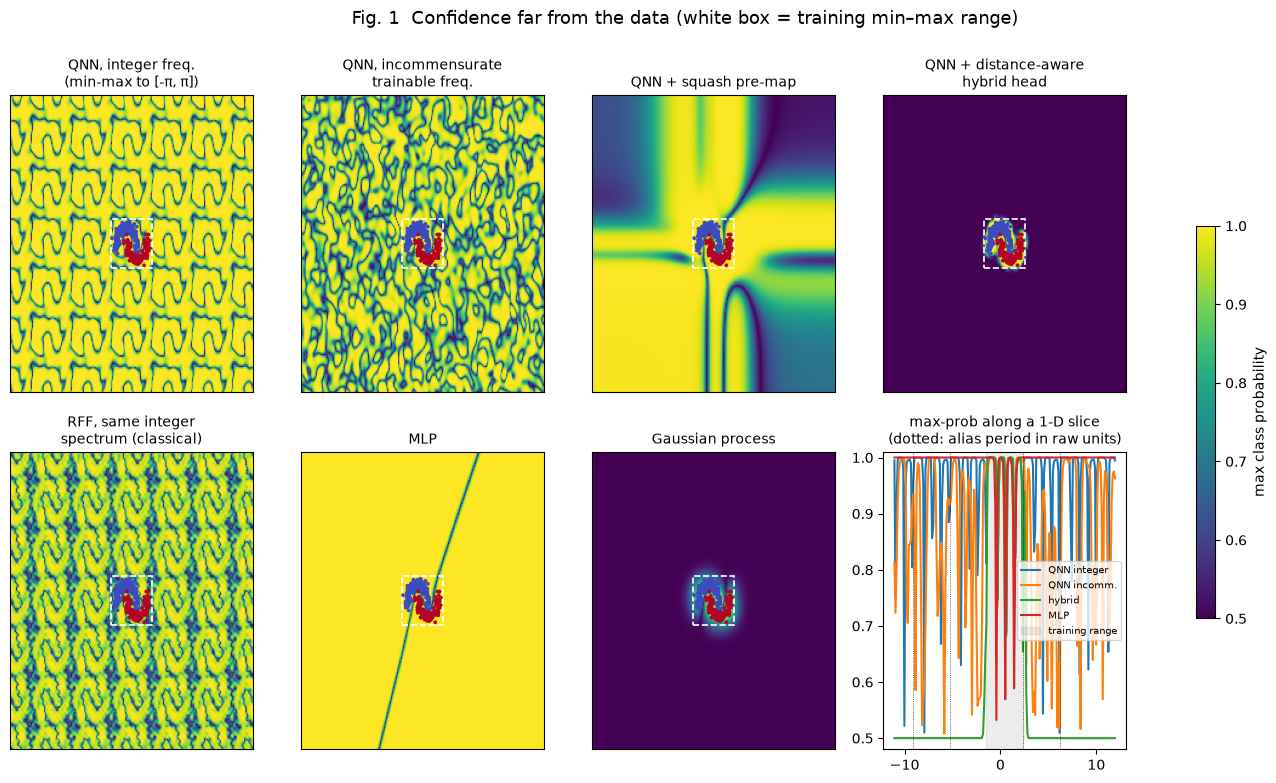

In [10]:
def figure_2d(cfg):
    if "synth2d" not in LOADED:
        return
    Ftr, ytr, Fte, yte, Ffar, C = split_features(LOADED["synth2d"], 0, cfg["n_train"], cfg["n_test"])
    prep, nq, L = Prep(Ftr), QUBITS["synth2d"], cfg["n_layers"]
    u = prep.to_u(Ftr, cfg["scalings"]["sym"])
    fit = lambda uu, **kw: QNN(nq, L, 2, C, seed=0, lr=cfg["lr"], **kw).fit(uu, ytr, cfg["epochs"], cfg["batch"])
    base = QNNWrap(fit(u), prep, "sym", cfg)
    mods = {
        "QNN, integer freq.\n(min-max to [-π, π])": base,
        "QNN, incommensurate\ntrainable freq.": QNNWrap(fit(u, trainable_freq=True), prep, "sym", cfg),
        "QNN + squash pre-map": QNNWrap(fit(prep.to_squash(Ftr, cfg["squash_s"])), prep, "squash", cfg),
        "QNN + distance-aware\nhybrid head": HybridWrap(base, u, cfg["knn_k"]),
        "RFF, same integer\nspectrum (classical)": SkWrap("rff", prep, cfg, 0, C, 2, nq, L).fit(Ftr, ytr),
        "MLP": SkWrap("mlp", prep, cfg, 0, C, 2, nq, L).fit(Ftr, ytr),
        "Gaussian process": SkWrap("gp", prep, cfg, 0, C, 2, nq, L).fit(Ftr, ytr),
    }
    span = prep.mx - prep.mn
    g = cfg["grid"]
    xs = np.linspace(prep.mn[0] - 2.5 * span[0], prep.mx[0] + 2.5 * span[0], g)
    ys = np.linspace(prep.mn[1] - 2.5 * span[1], prep.mx[1] + 2.5 * span[1], g)
    XX, YY = np.meshgrid(xs, ys)
    G = np.c_[XX.ravel(), YY.ravel()]
    fig, axes = plt.subplots(2, 4, figsize=(18, 8.5))
    for ax, (title, m) in zip(axes.ravel(), mods.items()):
        sc, P = m.scores(G) if not isinstance(m, QNNWrap) else m.scores(G, with_grad=False)
        im = ax.imshow(P.max(1).reshape(g, g), origin="lower", extent=[xs[0], xs[-1], ys[0], ys[-1]],
                       vmin=1 / C, vmax=1, cmap="viridis", aspect="auto")
        ax.add_patch(plt.Rectangle((prep.mn[0], prep.mn[1]), span[0], span[1], fill=False, ec="w", lw=1.2, ls="--"))
        ax.scatter(Ftr[:300, 0], Ftr[:300, 1], c=ytr[:300], s=3, cmap="coolwarm")
        ax.set_title(title, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
    ax = axes.ravel()[-1]
    # 1-D slice: max-prob along a horizontal line through the data, QNN vs incommensurate vs MLP
    line = np.c_[xs, np.full(g, np.median(Ftr[:, 1]))]
    for title, key in [("QNN integer", list(mods)[0]), ("QNN incomm.", list(mods)[1]),
                       ("hybrid", list(mods)[3]), ("MLP", "MLP")]:
        m = mods[key]
        P = (m.scores(line, with_grad=False) if isinstance(m, QNNWrap) else m.scores(line))[1]
        ax.plot(xs, P.max(1), label=title)
    ax.axvspan(prep.mn[0], prep.mx[0], color="grey", alpha=0.15, label="training range")
    for kk in range(-2, 3):
        if kk:
            ax.axvline(prep.mn[0] + kk * span[0], color="k", lw=0.5, ls=":")
    ax.set_title("max-prob along a 1-D slice\n(dotted: alias period in raw units)", fontsize=10)
    ax.legend(fontsize=7); ax.set_ylim(1 / C - 0.02, 1.01)
    fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.6, label="max class probability")
    fig.suptitle("Fig. 1  Confidence far from the data (white box = training min–max range)", fontsize=13)
    fig.savefig(os.path.join(RES, "figures", "fig1_synth2d_confidence_maps.png"), dpi=150, bbox_inches="tight")
    plt.show()

try:
    figure_2d(CFG)
except Exception:
    log("ERROR fig1:\n" + traceback.format_exc())

## E4 — Recurrence distance: incommensurate frequencies only make aliasing approximate

D(T) = mean over ID points of max_c |p_c(x + T·e) − p_c(x)| for shifts T along one encoded axis.
Integer frequencies: D = 0 exactly at T = 2πm. Incommensurate: quasi-periodic, D dips near zero again
at larger T (Kronecker/Bohr). We report, for ε ∈ {0.01, 0.05, 0.1}, the smallest T > 2π with D(T) ≤ ε.

[14:04:31] E4 recurrence done for synth2d
[14:06:03] E4 recurrence done for wine_red_white
[14:07:16] E4 recurrence done for digits_split


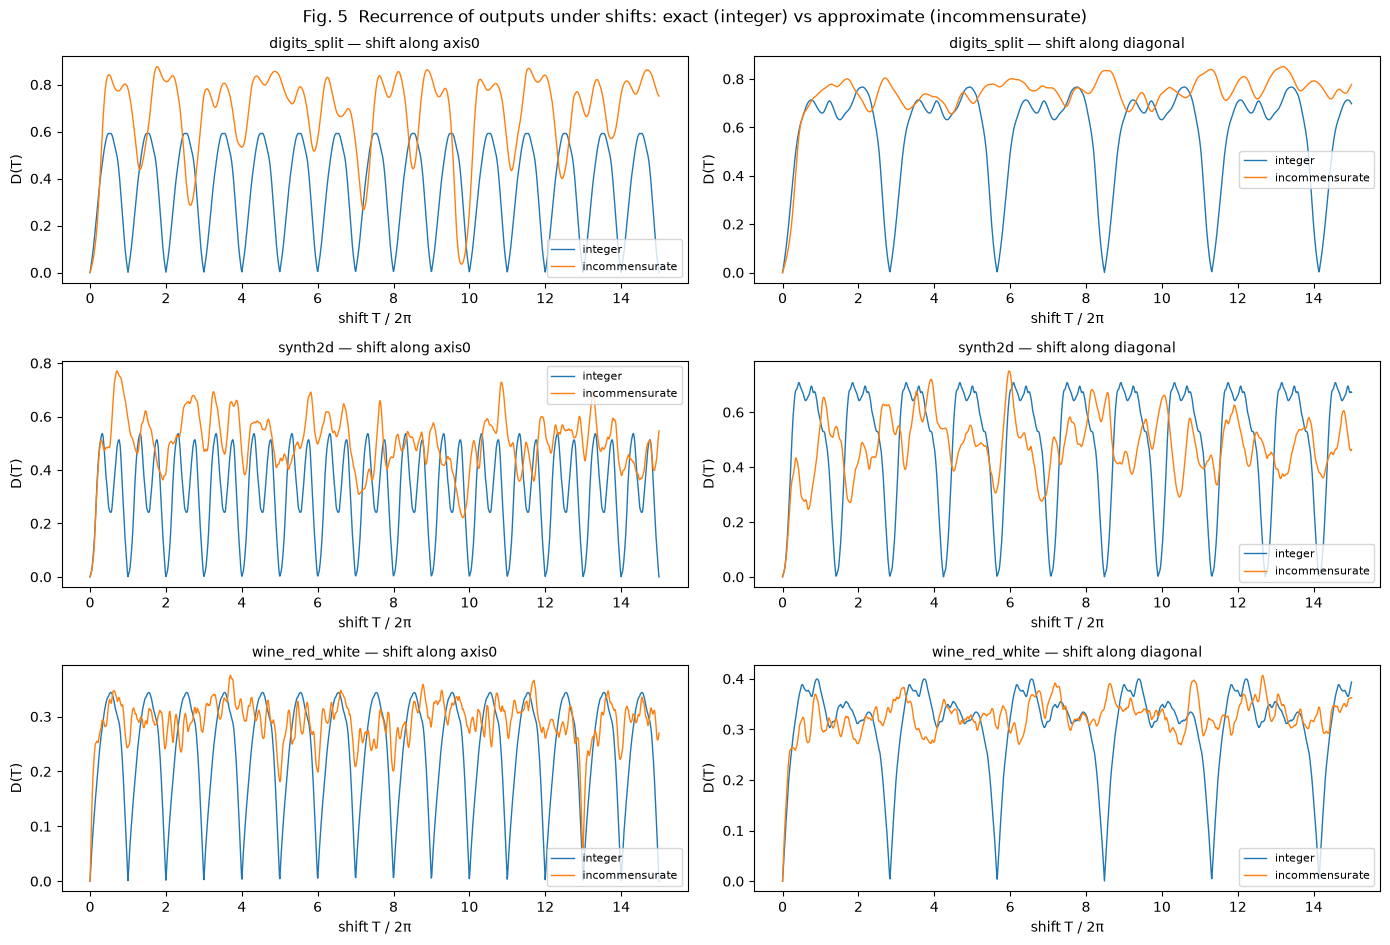

           dataset           model direction   eps  first_recurrence_T  \
0          synth2d         integer     axis0  0.01            6.287377   
1          synth2d         integer     axis0  0.05            6.287377   
2          synth2d         integer     axis0  0.10            6.287377   
3          synth2d         integer  diagonal  0.01            8.865201   
4          synth2d         integer  diagonal  0.05            8.676580   
5          synth2d         integer  diagonal  0.10            8.487959   
6          synth2d  incommensurate     axis0  0.01                 NaN   
7          synth2d  incommensurate     axis0  0.05                 NaN   
8          synth2d  incommensurate     axis0  0.10                 NaN   
9          synth2d  incommensurate  diagonal  0.01                 NaN   
10         synth2d  incommensurate  diagonal  0.05                 NaN   
11         synth2d  incommensurate  diagonal  0.10                 NaN   
12         synth2d   learned_omega    

In [11]:
def recurrence(cfg):
    rows, curves = [], {}
    for ds in [d for d in ["synth2d", "wine_red_white", "digits_split"] if d in LOADED]:
        Ftr, ytr, Fte, yte, Ffar, C = split_features(LOADED[ds], 0, cfg["n_train"], cfg["n_test"])
        prep, nq, L = Prep(Ftr), QUBITS.get(ds, DEFAULT_QUBITS), cfg["n_layers"]
        u = prep.to_u(Ftr, cfg["scalings"]["sym"])
        ute = prep.to_u(Fte, cfg["scalings"]["sym"])[: cfg["recurrence_points"]]
        Tmax = 30 * np.pi
        Ts = np.linspace(0, Tmax, cfg["recurrence_shifts"])
        for tag, kw in [("integer", {}), ("incommensurate", dict(trainable_freq=True))]:
            q = QNN(nq, L, u.shape[1], C, seed=0, lr=cfg["lr"], **kw).fit(u, ytr, cfg["epochs"], cfg["batch"])
            P0 = softmax(q.logits(ute), 1)
            for axis_name, e in [("axis0", np.eye(u.shape[1])[0]),
                                 ("diagonal", np.ones(u.shape[1]) / np.sqrt(u.shape[1]))]:
                D = np.empty(len(Ts))
                for i, T in enumerate(Ts):
                    D[i] = np.abs(softmax(q.logits(ute + T * e), 1) - P0).max(1).mean()
                curves[(ds, tag, axis_name)] = D
                for eps in [0.01, 0.05, 0.1]:
                    hit = np.where((Ts > TWO_PI * 0.999) & (D <= eps))[0]
                    rows.append(dict(dataset=ds, model=tag, direction=axis_name, eps=eps,
                                     first_recurrence_T=float(Ts[hit[0]]) if len(hit) else np.nan,
                                     first_recurrence_in_periods=float(Ts[hit[0]] / TWO_PI) if len(hit) else np.nan,
                                     min_D_beyond_2pi=float(D[Ts > TWO_PI * 0.999].min()), T_max=Tmax))
            if tag == "incommensurate":
                rows.append(dict(dataset=ds, model="learned_omega", direction="-", eps=np.nan,
                                 first_recurrence_T=np.nan, first_recurrence_in_periods=np.nan,
                                 min_D_beyond_2pi=np.nan, T_max=Tmax,
                                 note=json.dumps(np.round(q.p["omega"], 4).tolist())))
        log(f"E4 recurrence done for {ds}")
    df = pd.DataFrame(rows)
    df.to_csv(os.path.join(RES, "recurrence_summary.csv"), index=False)
    cur = pd.DataFrame({"T": Ts, **{"|".join(k): v for k, v in curves.items()}})
    cur.to_csv(os.path.join(RES, "recurrence_curves.csv"), index=False)
    dss = sorted({k[0] for k in curves})
    fig, axes = plt.subplots(len(dss), 2, figsize=(14, 3.2 * len(dss)), squeeze=False)
    for i, ds in enumerate(dss):
        for j, ax_name in enumerate(["axis0", "diagonal"]):
            ax = axes[i, j]
            for tag in ["integer", "incommensurate"]:
                ax.plot(Ts / TWO_PI, curves[(ds, tag, ax_name)], label=tag, lw=1)
            ax.set_title(f"{ds} — shift along {ax_name}", fontsize=10)
            ax.set_xlabel("shift T / 2π"); ax.set_ylabel("D(T)"); ax.legend(fontsize=8)
    fig.suptitle("Fig. 5  Recurrence of outputs under shifts: exact (integer) vs approximate (incommensurate)")
    fig.tight_layout()
    fig.savefig(os.path.join(RES, "figures", "fig5_recurrence.png"), dpi=150, bbox_inches="tight")
    plt.show()
    return df

try:
    REC = recurrence(CFG)
    display(REC) if "display" in globals() else print(REC)
except Exception:
    log("ERROR E4:\n" + traceback.format_exc())

## Aggregate results, tables and figures

In [12]:
def load_parts(suffix):
    fs = sorted(f for f in os.listdir(os.path.join(RES, "parts")) if f.endswith(suffix))
    return pd.concat([pd.read_csv(os.path.join(RES, "parts", f)) for f in fs], ignore_index=True) if fs else pd.DataFrame()

MET, ACC, STATS = load_parts("_metrics.csv"), load_parts("_accuracy.csv"), load_parts("_setstats.csv")
MET.to_csv(os.path.join(RES, "all_metrics_long.csv"), index=False)
ACC.to_csv(os.path.join(RES, "all_accuracy.csv"), index=False)
STATS.to_csv(os.path.join(RES, "all_ood_set_stats.csv"), index=False)

def ms(x):
    return f"{np.mean(x):.3f}±{np.std(x):.3f}" if len(x) > 1 else f"{np.mean(x):.3f}"

if len(MET):
    summ = MET.groupby(["dataset", "model", "scaling", "score", "ood_set"]).agg(
        auroc_mean=("auroc", "mean"), auroc_std=("auroc", "std"),
        fpr95_mean=("fpr95", "mean"), fpr95_std=("fpr95", "std"), n_seeds=("seed", "nunique")).reset_index()
    summ.to_csv(os.path.join(RES, "summary_auroc_fpr95.csv"), index=False)

    # Table 1: alias theorem — AUROC on the exact alias set
    T1 = MET[MET.ood_set.str.startswith("alias_")].groupby(["model", "scaling", "score", "ood_set"])["auroc"].agg(ms).unstack("ood_set")
    T1.to_csv(os.path.join(RES, "table1_exact_alias_auroc.csv"))
    print("Table 1 — AUROC on exact alias sets (0.500 = blind). Periodic models must sit at 0.5:")
    display(T1) if "display" in globals() else print(T1)

    # Table 2: accuracy vs OOD trade-off
    shift_sets = MET[~MET.ood_set.str.startswith("alias_")]
    best = shift_sets.groupby(["dataset", "seed", "model", "scaling", "score"])["auroc"].mean().reset_index()
    T2 = best.groupby(["model", "scaling", "score"])["auroc"].mean().rename("mean_auroc_all_shifts").reset_index()
    acc_m = ACC.groupby(["model", "scaling"])["accuracy"].mean().reset_index()
    T2 = T2.merge(acc_m, on=["model", "scaling"], how="left").sort_values("mean_auroc_all_shifts", ascending=False)
    T2.to_csv(os.path.join(RES, "table2_tradeoff.csv"), index=False)
    print("\nTable 2 — mean AUROC over all shift/far sets vs ID accuracy:")
    display(T2) if "display" in globals() else print(T2)

    T3 = STATS.groupby(["dataset", "scaling", "ood_set"])[["frac_out_of_range", "frac_aliased",
                                                             "frac_aliased_given_oor", "torus_coverage"]].mean()
    T3.to_csv(os.path.join(RES, "table3_alias_frequency.csv"))
    print("\nTable 3 — how often shifted data lands on aliases:")
    display(T3) if "display" in globals() else print(T3)

    acc_tab = ACC.groupby(["dataset", "model", "scaling"])["accuracy"].agg(ms).unstack("dataset")
    acc_tab.to_csv(os.path.join(RES, "table4_accuracy.csv"))

Table 1 — AUROC on exact alias sets (0.500 = blind). Periodic models must sit at 0.5:
ood_set                      alias_half    alias_sym
model      scaling score                            
gp         sym     msp      0.990±0.035  0.989±0.035
knn        sym     dist     1.000±0.000  1.000±0.000
mlp        sym     energy   0.312±0.268  0.312±0.257
                   msp      0.047±0.032  0.081±0.047
mlp_ens    sym     ens_var  0.507±0.183  0.527±0.168
                   msp      0.385±0.204  0.410±0.190
qnn        half    energy   0.500±0.000  0.652±0.165
                   grad     0.500±0.000  0.682±0.127
                   msp      0.500±0.000  0.672±0.142
           sym     energy   0.500±0.000  0.500±0.000
                   grad     0.500±0.000  0.500±0.000
                   msp      0.500±0.000  0.500±0.000
qnn_ens    half    energy   0.500±0.000  0.867±0.094
                   ens_var  0.500±0.000  0.941±0.043
                   msp      0.500±0.000  0.887±0.071
           sy

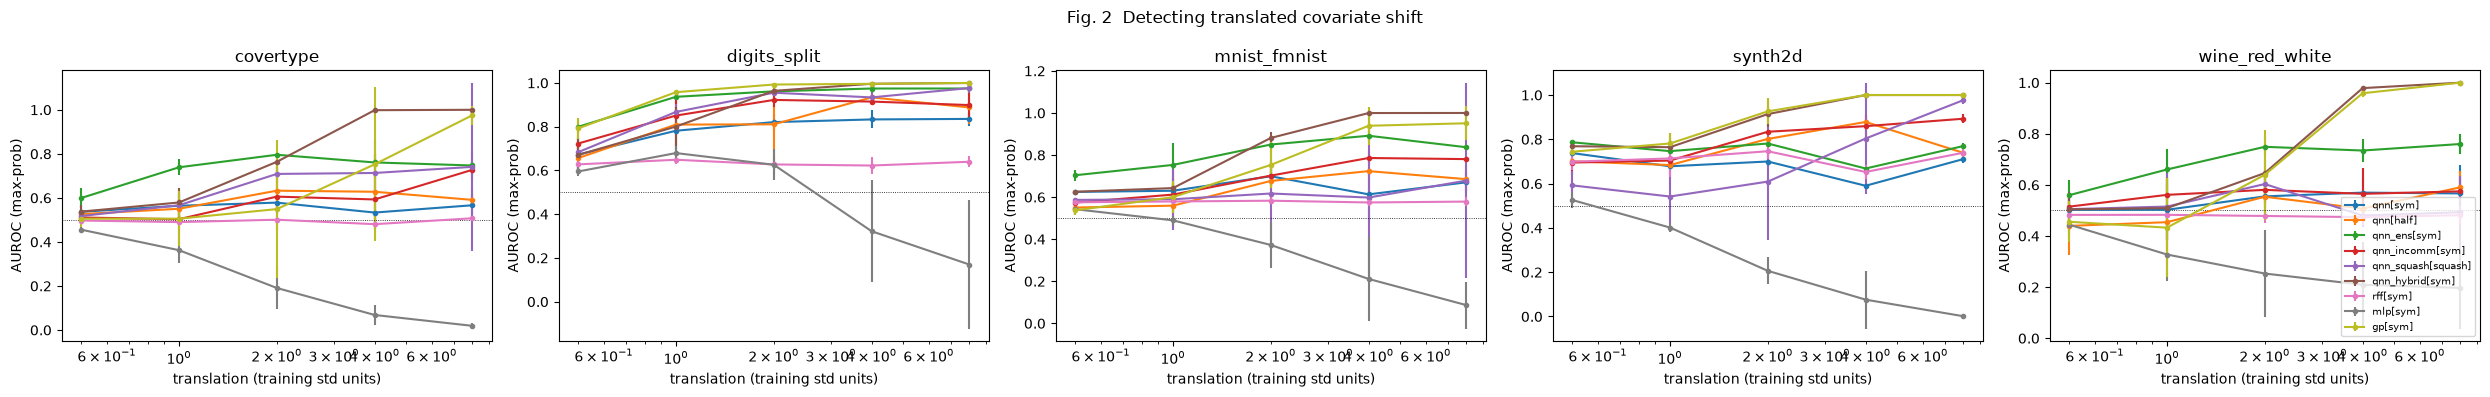

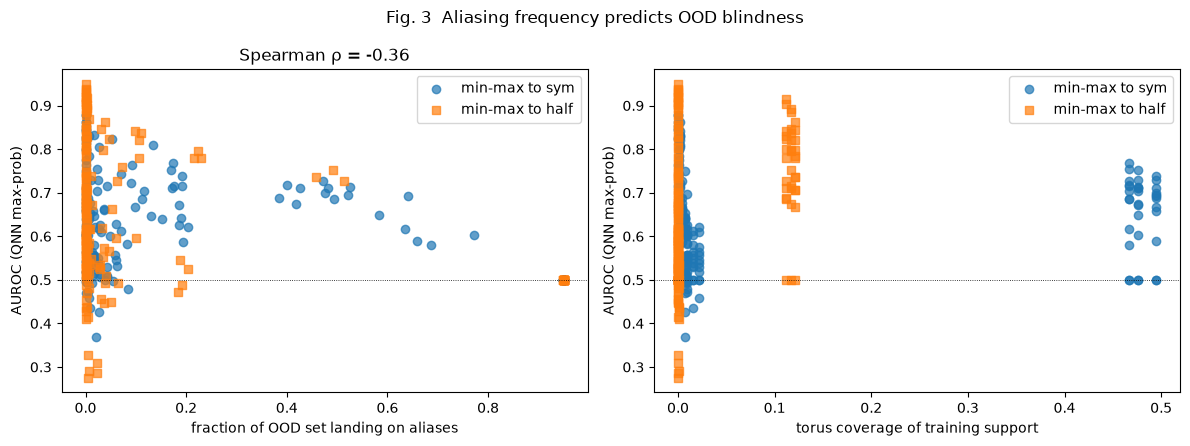

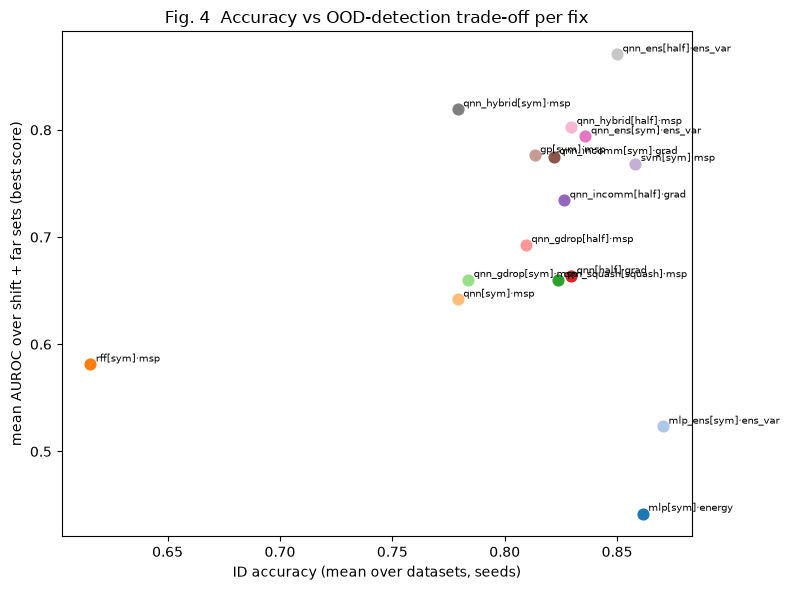

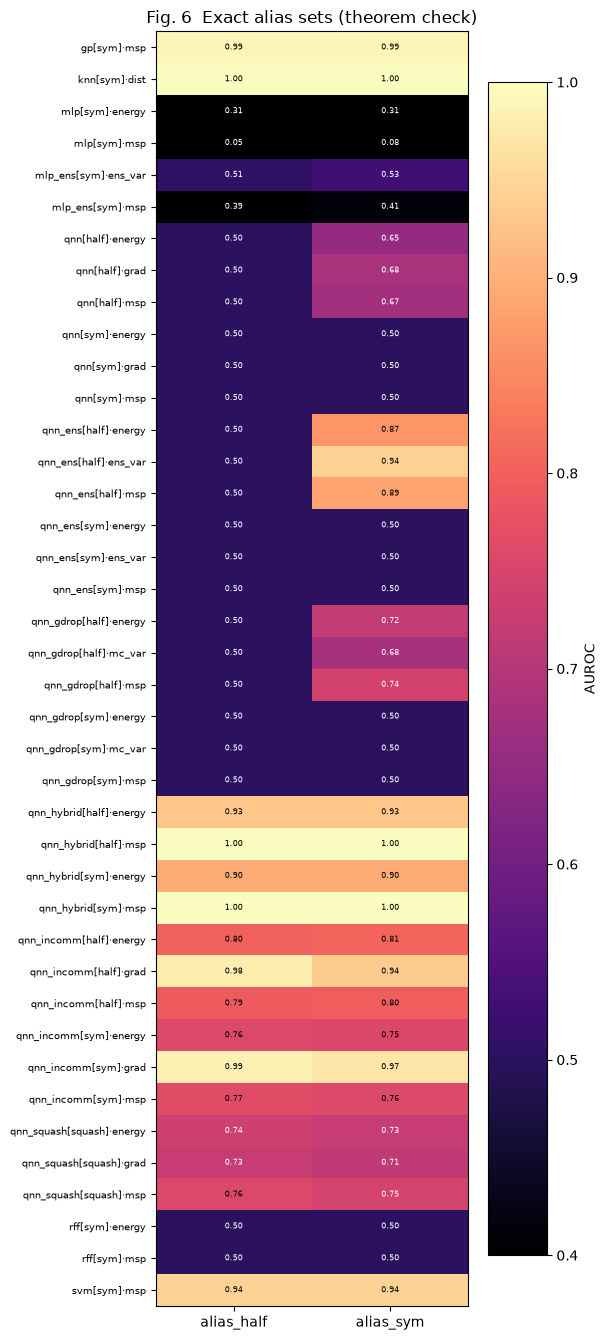

In [13]:
def plots():
    if not len(MET):
        return
    pal = plt.cm.tab20(np.linspace(0, 1, 20))
    # Fig 2: AUROC (msp) vs translation magnitude
    dss = sorted(MET.dataset.unique())
    fig, axes = plt.subplots(1, len(dss), figsize=(5 * len(dss), 4), squeeze=False)
    sel_models = [("qnn", "sym"), ("qnn", "half"), ("qnn_ens", "sym"), ("qnn_incomm", "sym"),
                  ("qnn_squash", "squash"), ("qnn_hybrid", "sym"), ("rff", "sym"), ("mlp", "sym"), ("gp", "sym")]
    for ax, ds in zip(axes[0], dss):
        D = MET[(MET.dataset == ds) & MET.ood_set.str.startswith("translate_")]
        for i, (m, sc) in enumerate(sel_models):
            sc_name = "msp"
            E = D[(D.model == m) & (D.scaling == sc) & (D.score == sc_name)].copy()
            if not len(E):
                continue
            E["t"] = E.ood_set.str.split("_").str[1].astype(float)
            g = E.groupby("t")["auroc"].agg(["mean", "std"]).reset_index()
            ax.errorbar(g.t, g["mean"], yerr=g["std"].fillna(0), label=f"{m}[{sc}]", marker="o", ms=3, color=pal[i * 2])
        ax.axhline(0.5, color="k", lw=0.6, ls=":")
        ax.set_xscale("log"); ax.set_title(ds); ax.set_xlabel("translation (training std units)"); ax.set_ylabel("AUROC (max-prob)")
    axes[0][-1].legend(fontsize=7, loc="lower right")
    fig.suptitle("Fig. 2  Detecting translated covariate shift")
    fig.tight_layout(); fig.savefig(os.path.join(RES, "figures", "fig2_auroc_vs_translation.png"), dpi=150); plt.show()

    # Fig 3: fraction aliased vs AUROC of the base QNN
    M = MET[(MET.model == "qnn") & (MET.score == "msp")].merge(
        STATS, on=["dataset", "seed", "scaling", "ood_set"])
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for sc, mk in [("sym", "o"), ("half", "s")]:
        E = M[M.scaling == sc]
        axes[0].scatter(E.frac_aliased, E.auroc, marker=mk, alpha=0.7, label=f"min-max to {sc}")
        axes[1].scatter(E.torus_coverage, E.auroc, marker=mk, alpha=0.7, label=f"min-max to {sc}")
    axes[0].set_xlabel("fraction of OOD set landing on aliases"); axes[1].set_xlabel("torus coverage of training support")
    for a in axes:
        a.set_ylabel("AUROC (QNN max-prob)"); a.axhline(0.5, color="k", lw=0.6, ls=":"); a.legend()
    rho = M[["frac_aliased", "auroc"]].corr(method="spearman").iloc[0, 1]
    axes[0].set_title(f"Spearman ρ = {rho:.2f}")
    fig.suptitle("Fig. 3  Aliasing frequency predicts OOD blindness")
    fig.tight_layout(); fig.savefig(os.path.join(RES, "figures", "fig3_alias_fraction_vs_auroc.png"), dpi=150); plt.show()

    # Fig 4: accuracy vs OOD trade-off
    fig, ax = plt.subplots(figsize=(8, 6))
    best_score = T2.sort_values("mean_auroc_all_shifts").groupby(["model", "scaling"]).tail(1)
    for i, r in enumerate(best_score.itertuples()):
        ax.scatter(r.accuracy, r.mean_auroc_all_shifts, color=pal[i % 20], s=60)
        ax.annotate(f"{r.model}[{r.scaling}]·{r.score}", (r.accuracy, r.mean_auroc_all_shifts), fontsize=7,
                    xytext=(4, 2), textcoords="offset points")
    ax.set_xlabel("ID accuracy (mean over datasets, seeds)"); ax.set_ylabel("mean AUROC over shift + far sets (best score)")
    ax.set_title("Fig. 4  Accuracy vs OOD-detection trade-off per fix")
    fig.tight_layout(); fig.savefig(os.path.join(RES, "figures", "fig4_tradeoff.png"), dpi=150); plt.show()

    # Fig 6: exact alias heatmap
    H = MET[MET.ood_set.str.startswith("alias_")].groupby(["model", "scaling", "score", "ood_set"])["auroc"].mean().unstack("ood_set")
    fig, ax = plt.subplots(figsize=(6, 0.3 * len(H) + 1.5))
    im = ax.imshow(H.values, vmin=0.4, vmax=1.0, cmap="magma", aspect="auto")
    ax.set_yticks(range(len(H))); ax.set_yticklabels([f"{a}[{b}]·{c}" for a, b, c in H.index], fontsize=7)
    ax.set_xticks(range(H.shape[1])); ax.set_xticklabels(H.columns)
    for i in range(H.shape[0]):
        for j in range(H.shape[1]):
            ax.text(j, i, f"{H.values[i, j]:.2f}", ha="center", va="center", fontsize=6,
                    color="w" if H.values[i, j] < 0.75 else "k")
    fig.colorbar(im, label="AUROC"); ax.set_title("Fig. 6  Exact alias sets (theorem check)")
    fig.tight_layout(); fig.savefig(os.path.join(RES, "figures", "fig6_exact_alias_heatmap.png"), dpi=150); plt.show()

try:
    plots()
except Exception:
    log("ERROR plots:\n" + traceback.format_exc())

## E2b — Corrected alias frequency (no retraining)

The first metric counted a point as "aliased" if it was out of range and close to the training
support on the torus. Points just past the boundary pass that test without wrapping, so the metric
overcounted. A point is now **aliased** only if it is close to the training data on the torus but
far from it in unwrapped space, i.e. it is near the training data *only because of wrap-around*.
Run this cell after the notebook has finished (it reuses LOADED, split_features, Prep,
build_ood_sets, torus_knn) and then re-run the zip cell.

In [14]:
def alias_stats_v2(u_tr, u_id, u_ood, rng_bounds, k=5):
    lo, hi = rng_bounds
    nn = NearestNeighbors(n_neighbors=k).fit(u_tr)
    tau_t = np.percentile(torus_knn(u_id, u_tr, k), 95)           # support radius on the torus
    tau_e = np.percentile(nn.kneighbors(u_id)[0].mean(1), 95)     # support radius without wrapping
    d_t = torus_knn(u_ood, u_tr, k)
    d_e = nn.kneighbors(u_ood)[0].mean(1)
    oor = np.any((u_ood < lo - 1e-9) | (u_ood > hi + 1e-9), axis=1)
    near_torus = d_t <= tau_t
    near_plain = d_e <= tau_e
    aliased = oor & near_torus & ~near_plain
    return dict(frac_out_of_range=float(oor.mean()),
                frac_near_without_wrap=float(near_plain.mean()),
                frac_aliased_v2=float(aliased.mean()),
                frac_aliased_v2_given_oor=float(aliased.sum() / max(oor.sum(), 1)))

rows_v2 = []
for ds, data in LOADED.items():
    for seed in CFG["seeds"]:
        Ftr, ytr, Fte, yte, Ffar, C = split_features(data, seed, CFG["n_train"], CFG["n_test"])
        prep = Prep(Ftr)
        sets = build_ood_sets(Fte, Ffar, prep, CFG, seed, data["far_name"])
        for sc, r in CFG["scalings"].items():
            u_tr, u_te = prep.to_u(Ftr, r), prep.to_u(Fte, r)
            for name, Fo in sets.items():
                rows_v2.append(dict(dataset=ds, seed=seed, scaling=sc, ood_set=name,
                                    **alias_stats_v2(u_tr, u_te, prep.to_u(Fo, r), r)))
    log(f"E2b alias stats v2 done for {ds}")

STATS2 = pd.DataFrame(rows_v2)
STATS2.to_csv(os.path.join(RES, "all_ood_set_stats_v2.csv"), index=False)
T3b = STATS2.groupby(["dataset", "scaling", "ood_set"])[
    ["frac_out_of_range", "frac_aliased_v2", "frac_aliased_v2_given_oor"]].mean()
T3b.to_csv(os.path.join(RES, "table3b_alias_frequency_corrected.csv"))
J2 = MET[(MET.model == "qnn") & (MET.score == "msp")].merge(STATS2, on=["dataset", "seed", "scaling", "ood_set"])
from scipy.stats import spearmanr
nat2 = J2[~J2.ood_set.str.startswith("alias_")]
r2 = spearmanr(nat2.frac_aliased_v2, nat2.auroc)
log(f"E2b Spearman(frac_aliased_v2, QNN msp AUROC) on natural shifts: rho={r2.correlation:.3f}, p={r2.pvalue:.2g}")
display(T3b) if "display" in globals() else print(T3b)

[14:07:31] E2b alias stats v2 done for synth2d
[14:07:36] E2b alias stats v2 done for wine_red_white
[14:07:56] E2b alias stats v2 done for mnist_fmnist
[14:08:19] E2b alias stats v2 done for covertype
[14:08:21] E2b alias stats v2 done for digits_split
[14:08:21] E2b Spearman(frac_aliased_v2, QNN msp AUROC) on natural shifts: rho=0.068, p=0.24
                                                frac_out_of_range  \
dataset        scaling ood_set                                      
covertype      half    alias_half                        1.000000   
                       alias_sym                         1.000000   
                       far:covtype_classes3to7           0.156000   
                       scale_1.5                         0.256667   
                       scale_2                           0.659000   
...                                                           ...   
wine_red_white sym     translate_0.5                     0.029393   
                       translate

## Package everything into a zip for further analysis

In [15]:
def write_readme():
    lines = [
        "# Results: aliasing blind spots in re-uploading QNNs", "",
        f"Generated {datetime.datetime.now().isoformat(timespec='seconds')}  |  MODE={MODE}", "",
        f"Datasets run: {sorted(LOADED)}  |  skipped: {SKIPPED}", "",
        "## Files",
        "- `config.json` — every hyperparameter used.",
        "- `sanity_checks.json` — adjoint-gradient error vs finite differences; max output change under exact 2πk shifts.",
        "- `all_metrics_long.csv` — one row per (dataset, seed, model, scaling, score, ood_set): AUROC, FPR@95.",
        "- `summary_auroc_fpr95.csv` — mean/std over seeds.",
        "- `all_accuracy.csv`, `table4_accuracy.csv` — ID test accuracy.",
        "- `all_ood_set_stats.csv`, `table3_alias_frequency.csv` — v1 alias metric (overcounts points just past the boundary; superseded).",
        "- `all_ood_set_stats_v2.csv`, `table3b_alias_frequency_corrected.csv` — corrected alias metric: near the data only via wrap-around.",
        "- `table1_exact_alias_auroc.csv` — theorem check: periodic models must score 0.5 on `alias_*` sets.",
        "- `table2_tradeoff.csv` — mean AUROC over shift/far sets vs accuracy.",
        "- `recurrence_summary.csv`, `recurrence_curves.csv` — E4 quasi-periodic recurrence.",
        "- `scores/<dataset>_seed<k>.npz` — per-sample OOD scores; keys `model|scaling|score|set` (set `ID` = in-distribution test).",
        "- `figures/` — fig1 confidence maps, fig2 AUROC vs translation, fig3 alias fraction vs AUROC, fig4 trade-off, fig5 recurrence, fig6 alias heatmap.",
        "- `run_log.txt`, `environment.json`.", "",
        "## Naming",
        "- scaling: `sym` = min-max to [-π, π]; `half` = [0, π]; `squash` = (π/2)·tanh(z/s); classical baselines use `sym` (affine, no wrapping).",
        "- models: `qnn` (integer freq.), `qnn_ens` (ensemble), `qnn_gdrop` (Gaussian parameter noise, MC), `qnn_incomm` (trainable incommensurate freq.),",
        "  `qnn_squash`, `qnn_hybrid` (distance-gated logits), `rff` (random Fourier features on the QNN integer spectrum), `mlp`, `mlp_ens`, `svm`, `gp`, `knn` (distance only).",
        "- scores (higher = more OOD): `msp` = −max prob, `energy` = −logsumexp(logits), `ens_var`, `mc_var`, `grad` = per-sample parameter-gradient norm (extrapolation-score proxy), `dist` = kNN distance.",
        "- OOD sets: `translate_t` (shift by t training std, random sign per feature), `scale_s` (μ + s(x−μ)), `far:*` (other dataset/classes),",
        "  `alias_sym` / `alias_half` (exact lattice shifts u + 2πk for that scaling, mapped back to feature space).",
    ]
    with open(os.path.join(RES, "README.md"), "w") as f:
        f.write("\n".join(lines))
    env = dict(python=sys.version, platform=platform.platform(), numpy=np.__version__, pandas=pd.__version__,
               sklearn=__import__("sklearn").__version__, matplotlib=matplotlib.__version__, cpu_count=os.cpu_count())
    with open(os.path.join(RES, "environment.json"), "w") as f:
        json.dump(env, f, indent=2)

write_readme()
stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
ZIP_PATH = f"qnn_aliasing_results_{MODE}_{stamp}.zip"
with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, files in os.walk(RES):
        for fn in files:
            p = os.path.join(root, fn)
            z.write(p, os.path.relpath(p, os.path.dirname(os.path.abspath(RES))))
log(f"ZIP written: {os.path.abspath(ZIP_PATH)}  ({os.path.getsize(ZIP_PATH)/1e6:.1f} MB)")
try:
    from google.colab import files as _colab_files   # auto-download when running in Colab
    _colab_files.download(ZIP_PATH)
except Exception:
    pass

[14:08:22] ZIP written: /Users/atultripathi/Library/CloudStorage/OneDrive-manit.ac.in/Quantum_2/untitled folder/qnn_aliasing_results_FULL_20261018_140821.zip  (23.2 MB)
